# KASDAD TP2 — Classification Samuel Indriano

**Pendekatan akhir: C4_HGB dengan routing berdasarkan ketersediaan `signal_stream`.**

Notebook ini merangkum perkembangan eksperimen Classification Samuel dan menjalankan ulang satu evaluasi temporal secara langsung dari data Train resmi. Tujuannya menjelaskan keputusan metode dan memeriksa bahwa implementasi final dapat direproduksi tanpa cache eksperimen pribadi.

| Komponen | Keputusan |
|---|---|
| Target | `artifact_signal` — label biner 0/1 |
| Metrik utama | Macro F1, dengan F1 kedua kelas ditampilkan |
| Validasi yang dijalankan di sini | Fit cycle 47–75 → evaluasi cycle 76–79 |
| Kandidat yang dipertahankan | C4_HGB, threshold 0,50 |
| Kaggle | Public score 0,82641, submission ref 57808225; terpisah dari validasi internal |

**Batas evaluasi:** cycle 76–79 sudah muncul dalam eksperimen development Round 1/2. Refit pada blok ini adalah reproduksi pipeline end-to-end, bukan holdout baru atau bukti generalisasi yang independen. Notebook tidak melakukan Kaggle submission.

Untuk pengumpulan, panduan resmi meminta satu notebook Classification dan satu Regression per anggota. Nama standar Classification adalah `TP2_Classification_A06_KasdudLovers_SamuelIndriano_2406400524.ipynb`. Di repository, notebook tetap memakai nama kanonis Samuel; file export terpisah ditangani saat packaging.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "models").is_dir() and (candidate / "notebooks" / "samuel").is_dir():
            return candidate
    raise FileNotFoundError(
        "Folder repository KASDAD tidak ditemukan. Buka notebook dari dalam repository."
    )

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.paths import task_files
from src.models.classification_models import _array_digest
from src.models.classification_round2_models import build_round2_model, stream_missing_mask
from src.models.classification_round2_metrics import binary_metrics

# Some reporting modules select Agg at import time. Set the notebook
# display backend only after all project imports have completed.
get_ipython().run_line_magic("matplotlib", "inline")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
print("Repository:", PROJECT_ROOT)
print("Dataset default: data/raw/classification/ | Override: TP2_DATA_DIR ke root data/ yang berisi classification/")

Repository: C:\Users\Sam\AppData\Local\Temp\tp2_samuel_availability_t02im4wu
Dataset default: data/raw/classification/ | Override: TP2_DATA_DIR ke root data/ yang berisi classification/


## 1. Masalah, label, dan data

`artifact_signal` menandai apakah indikasi artefak eksploit publik teramati pada record. Label 1 berarti indikasi teramati; label 0 **bukan** bukti bahwa artefak pasti tidak ada. Data diberikan menurut waktu: Train mencakup cycle 47–79 dan official Test mencakup cycle 80–91. Karena target dapat bergeser menurut waktu, validasi menggunakan blok cycle utuh dengan masa lalu sebagai data fit.

Label 1 lebih jarang daripada label 0. Macro F1 memberi bobot yang sama pada F1 tiap kelas, sehingga kinerja kelas minoritas tidak tertutup oleh kelas mayoritas. Confusion matrix di bawah memakai baris = label aktual dan kolom = label prediksi.

TP2 memakai target baru dibanding TP1. Karena itu kegunaan fitur dan threshold diukur lagi pada target ini, tanpa menganggap recipe TP1 otomatis berlaku.

In [2]:
DATA_FILES = task_files("classification")
if DATA_FILES["train"] is None:
    raise FileNotFoundError(
        "Train.csv tidak ditemukan. Letakkan di data/raw/classification/ atau atur TP2_DATA_DIR ke direktori induk data."
    )

train_path = DATA_FILES["train"]
train = pd.read_csv(train_path)
required = {"artifact_signal", "cycle_code", "signal_stream", "entry_friction", "impact_load"}
missing_columns = sorted(required - set(train.columns))
assert not missing_columns, f"Kolom Train yang diperlukan tidak ada: {missing_columns}"
assert train["artifact_signal"].notna().all()
assert set(train["artifact_signal"].unique()) == {0, 1}
assert train["cycle_code"].between(47, 79).all()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

r1_freeze = json.loads((PROJECT_ROOT / "experiments/classification_round1/freeze.json").read_text(encoding="utf-8"))
r2_freeze = json.loads((PROJECT_ROOT / "experiments/classification_round2/freeze.json").read_text(encoding="utf-8"))
actual_train_sha256 = sha256_file(train_path)
expected_train_sha256 = r1_freeze["identity"]["input_sha256"]["train"]
assert actual_train_sha256 == expected_train_sha256, "Train bytes differ from the frozen classification input."
assert r2_freeze["identity"]["round1_freeze_signature"] == r1_freeze["signature"]

def normalized_source_sha256(relative_path):
    source = (PROJECT_ROOT / relative_path).read_bytes().replace(b"\r\n", b"\n")
    return hashlib.sha256(source).hexdigest()

required_source_refs = {
    "src/models/classification_models.py": r1_freeze["identity"]["code_sha256"],
    "src/models/round1_models.py": r1_freeze["identity"]["code_sha256"],
    "src/models/classification_round2_models.py": r2_freeze["identity"]["new_code_sha256"],
    "src/models/classification_round2_metrics.py": r2_freeze["identity"]["new_code_sha256"],
}
source_checks = []
for relative_path, frozen_map in required_source_refs.items():
    observed = normalized_source_sha256(relative_path)
    expected = frozen_map[relative_path]
    source_checks.append({"source": relative_path, "matches frozen source": observed == expected})
assert all(row["matches frozen source"] for row in source_checks), "A model source file differs from its experiment freeze."
display(pd.DataFrame(source_checks))

positive_count = int(train["artifact_signal"].sum())
overview = pd.DataFrame([
    {"Train rows": len(train), "feature columns": len(train.columns) - 1,
     "cycles": f"{train.cycle_code.min()}–{train.cycle_code.max()}",
     "class 0": int((train.artifact_signal == 0).sum()), "class 1": positive_count,
     "prevalence class 1": positive_count / len(train),
     "signal_stream kosong": int(stream_missing_mask(train[["signal_stream"]]).sum()),
     "stream kosong (%)": float(stream_missing_mask(train[["signal_stream"]]).mean())}
])
display(overview.style.format({"prevalence class 1": "{:.2%}", "stream kosong (%)": "{:.2%}"}))
print("SHA-256 Train:", actual_train_sha256)

,source,matches frozen source
0,src/models/classification_models.py,True
1,src/models/round1_models.py,True
2,src/models/classification_round2_models.py,True
3,src/models/classification_round2_metrics.py,True


,Train rows,feature columns,cycles,class 0,class 1,prevalence class 1,signal_stream kosong,stream kosong (%)
0,50608,18,47–79,33038,17570,34.72%,3404,6.73%


SHA-256 Train: 875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c


### Distribusi label per cycle

Grafik ini memberi konteks data; EDA availability Samuel diringkas pada bagian berikut dan tersedia lengkap di notebook12. Prevalence per cycle dapat berubah; model dan evaluasi karena itu mempertahankan urutan waktu.

,awal_rows,awal_positive_rate,akhir_rows,akhir_positive_rate
cycle_code,,,,
47,1342.0,0.273472,NaN,NaN
48,977.0,0.384852,NaN,NaN
49,1255.0,0.239044,NaN,NaN
77,NaN,NaN,2335.0,0.285225
78,NaN,NaN,2146.0,0.250233
79,NaN,NaN,2188.0,0.307587


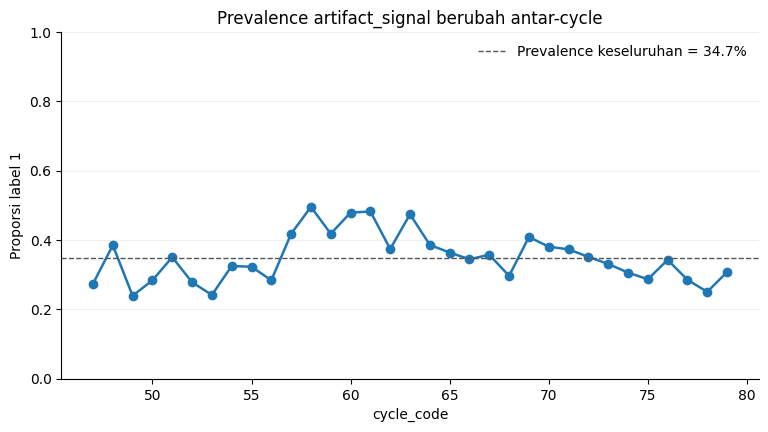

In [3]:
cycle_summary = (
    train.groupby("cycle_code", as_index=False)
    .agg(rows=("artifact_signal", "size"), positive_rate=("artifact_signal", "mean"))
)
fig, ax = plt.subplots()
ax.plot(cycle_summary.cycle_code, cycle_summary.positive_rate, marker="o", linewidth=1.8, color="#1f77b4")
ax.axhline(train.artifact_signal.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"Prevalence keseluruhan = {train.artifact_signal.mean():.1%}")
ax.set(title="Prevalence artifact_signal berubah antar-cycle", xlabel="cycle_code", ylabel="Proporsi label 1")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
early_cycles = cycle_summary.head(3).set_index("cycle_code").add_prefix("awal_")
late_cycles = cycle_summary.tail(3).set_index("cycle_code").add_prefix("akhir_")
display(pd.concat([early_cycles, late_cycles], axis=1))
plt.show()

### EDA individual Samuel — ketersediaan stream

Pertanyaan resmi: **Apakah proporsi `artifact_signal = 1` berbeda menurut ketersediaan
`signal_stream`, dan bagaimana perbedaannya berubah setelah mempertimbangkan periode
`cycle_code` serta volume narasi (`text_load`)?** Ringkasan berikut dihitung ulang dari
official Classification Train; detail eksplorasi, denominators, support, dan keterbatasan
ada di [notebook EDA availability](12_samuel_formal_eda_availability.ipynb).

EDA raw ini dikembangkan setelah model diagnostics. Hasil routing berasal dari eksperimen
modeling/error analysis sebelumnya; EDA ini memberi konteks komposisi, bukan penjelasan kausal.

,Kontras,Gap missing − present (pp),Coverage (%)
0,Marginal,3.66,100.00
1,Exact cycle,3.96,100.00
2,Periode × text_load q5,-2.30,100.00
3,Periode × text_load q10,-2.15,94.33


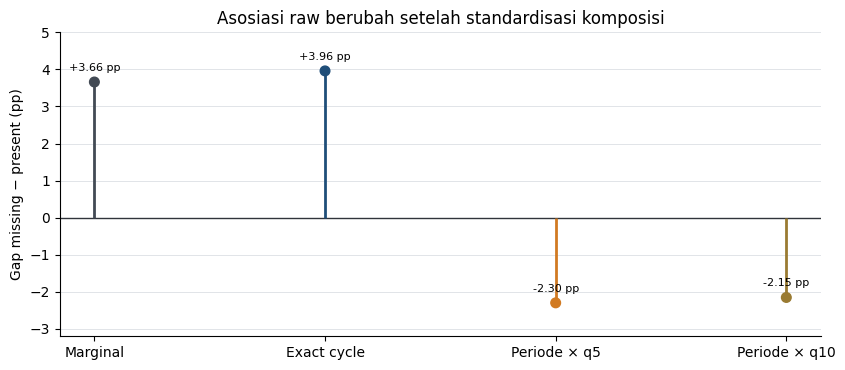

In [4]:
from src.eda.availability import (
    add_global_quantile_bins, prepare_availability_frame,
    prevalence_table, standardized_contrast,
)

eda_availability = prepare_availability_frame(train, stream_missing_mask(train))
eda_marginal = prevalence_table(eda_availability, ['availability']).set_index('availability')
eda_cycle, _ = standardized_contrast(eda_availability, ['cycle_code'], min_support=20)
eda_q5_frame, _ = add_global_quantile_bins(eda_availability, 5)
eda_period_q5, _ = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, _ = add_global_quantile_bins(eda_availability, 10)
eda_period_q10, _ = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)

eda_contrasts = pd.DataFrame([
    {'kontras':'Marginal', 'gap_pp':100*(eda_marginal.loc['missing','prevalence']-eda_marginal.loc['present','prevalence']), 'coverage':1.0},
    {'kontras':'Exact cycle', 'gap_pp':eda_cycle['standardized_missing_minus_present_pp'], 'coverage':eda_cycle['coverage_all_rows']},
    {'kontras':'Periode × text_load q5', 'gap_pp':eda_period_q5['standardized_missing_minus_present_pp'], 'coverage':eda_period_q5['coverage_all_rows']},
    {'kontras':'Periode × text_load q10', 'gap_pp':eda_period_q10['standardized_missing_minus_present_pp'], 'coverage':eda_period_q10['coverage_all_rows']},
])
eda_display = eda_contrasts.assign(**{'Coverage (%)':100*eda_contrasts.coverage}).drop(columns='coverage')
eda_display = eda_display.rename(columns={'kontras':'Kontras','gap_pp':'Gap missing − present (pp)'})
display(eda_display.round(2))
fig, ax = plt.subplots(figsize=(8.6,3.8))
x = np.arange(len(eda_contrasts)); values = eda_contrasts.gap_pp.to_numpy()
colors = ['#424a54','#1f4e79','#d17a22','#9a7b32']
ax.axhline(0,color='#30343b',lw=1); ax.vlines(x,0,values,color=colors,lw=2); ax.scatter(x,values,color=colors,s=48,zorder=3)
for i,row in eda_contrasts.iterrows():
    ax.annotate(f"{row.gap_pp:+.2f} pp",(i,row.gap_pp),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
ax.set_xticks(x,['Marginal','Exact cycle','Periode × q5','Periode × q10'])
ax.set_ylim(-3.2,5.0)
ax.set_ylabel('Gap missing − present (pp)'); ax.set_title('Asosiasi raw berubah setelah standardisasi komposisi')
ax.grid(axis='y',color='#e1e4e8',linewidth=.7); fig.tight_layout(); plt.show(); plt.close(fig)

Gap marginal **+3,66 pp** menjadi **+3,96 pp** setelah standardisasi exact cycle (seluruh Train didukung), lalu berbalik menjadi **−2,30 pp** pada periode × 5 kuantil volume dan **−2,15 pp** pada periode × 10 kuantil (coverage 94,33%). Bin volume bersifat kasar, common support tepat tidak sempurna, dan arah asosiasi bukan bukti sebab-akibat.

Secara terpisah, diagnostics modeling menunjukkan hybrid lebih lemah pada stream missing, sedangkan structured HGB lebih kuat pada subgroup itu; C4_HGB menggabungkan kedua cabang. Karena urutannya demikian, jangan menyajikan EDA ini sebagai penyebab ditemukannya routing atau klaim bahwa status missing mengubah target.

**Interpretasi.** Data Train memiliki dua kelas dengan prevalensi positif di bawah 50%. Plot memperlihatkan variasi antar-cycle, jadi satu random split berisiko mencampur masa depan ke dalam masa lalu. Semua preprocessing model di bawah dipelajari hanya dari baris fit cycle 47–75.

## 2. Perkembangan pendekatan

Eksperimen disusun untuk mengisolasi sumber informasi secara bertahap, bukan mengumpulkan algoritma tanpa alasan:

1. **Baseline dan fitur sederhana.** Majority, lookup `entry_friction`, serta Logistic Regression dua fitur menunjukkan bahwa fitur numerik awal saja belum cukup.
2. **Fitur structured yang diperluas.** Logistic Regression dan HistGradientBoosting (HGB) memberi baseline dengan numeric dan kategori, dengan preprocessing yang dipelajari dari fold fit.
3. **Teks.** TF-IDF Logistic Regression memberi kenaikan besar; menggabungkan structured dan teks (C2_B) meningkatkan primary Macro F1 lagi.
4. **Threshold dan missing stream.** Threshold dari inner history tidak selalu mengalahkan 0,50. Hybrid single-model juga lebih lemah saat `signal_stream` kosong.
5. **Availability routing.** C4_HGB memakai hybrid ketika teks tersedia dan structured HGB ketika teks kosong. Routing memakai ketersediaan fitur saja, bukan target.

Primary memakai enam expanding windows:47–55→56–59,47–59→60–63,47–63→64–67,47–67→68–71,47–71→72–75,47–75→76–79. H12_E47–55→56–67 dan H12_L47–67→68–79 memakai ulang record primary; H12 pooled bukan hanya H12_L. Seluruh Train telah dipakai development, bukan untouched holdout.

TF-IDF menggunakan word unigram + bigram, `min_df=3`, hingga 20.000 fitur dan `sublinear_tf=True`. Structured LR mempelajari scaler/OneHotEncoder hanya di training fold; HGB mempelajari imputasi dan kategori pada fold yang sama. Implementasi detail tetap berada di reusable `src/models/`.

,metode,Primary Macro F1,H12 Macro F1
recipe,,,
C0_A,Majority,0.38938,0.38938
C0_C,LR impact + EF,0.38938,0.38938
C1_A,LR structured,0.71453,0.67679
C1_B,HGB structured,0.73102,0.68906
C2_A,TF-IDF LR,0.80139,0.78192
C2_B,Hybrid LR,0.82063,0.78858
C4_HGB,Hybrid + HGB availability routing,0.82548,0.79681


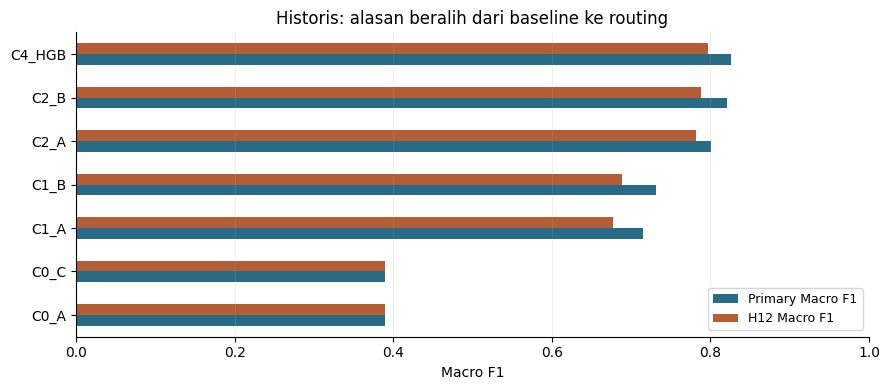

policy             fixed_0.5  inner_pooled
recipe keluarga                           
C2_B   H12 pooled     0.7886        0.7924
       Primary        0.8206        0.8188
C4_HGB H12 pooled     0.7968        0.7998
       Primary        0.8255        0.8236

,primary Macro F1,H12 Macro F1,primary stream-present F1,primary stream-missing F1,H12 stream-present F1,H12 stream-missing F1
recipe,,,,,,
C2_B,0.8206,0.7886,0.8286,0.7104,0.8005,0.6305
C4_LR,0.8242,0.7945,0.8286,0.7596,0.8005,0.7085
C4_HGB,0.8255,0.7968,0.8286,0.7817,0.8005,0.7450


In [5]:
def load_verified_history(round_name):
    folder = PROJECT_ROOT / f"reports/classification_{round_name}"
    result = json.loads((folder / "results.json").read_text(encoding="utf-8"))
    verification = json.loads((folder / "verification.json").read_text(encoding="utf-8"))
    assert verification["status"] == "PASS", f"{round_name} verification is not PASS"
    assert result["freeze_signature"] == verification["freeze_signature"]
    return result, verification

history_r1, verify_r1 = load_verified_history("round1")
history_r2, verify_r2 = load_verified_history("round2")

r1_primary = history_r1["aggregate"]["primary"]["fixed_0.5"]
r1_h12 = history_r1["aggregate"]["secondary"]["fixed_0.5"]
r2_primary = history_r2["aggregate"]["primary"]["fixed_0.5"]
r2_h12 = history_r2["aggregate"]["secondary"]["fixed_0.5"]
names = {"C0_A":"Majority", "C0_C":"LR impact + EF", "C1_A":"LR structured",
         "C1_B":"HGB structured", "C2_A":"TF-IDF LR", "C2_B":"Hybrid LR"}
evolution_rows=[]
for recipe, label in names.items():
    evolution_rows.append({"recipe":recipe,"metode":label,
        "Primary Macro F1":r1_primary[recipe]["metrics"]["macro_f1"],
        "H12 Macro F1":r1_h12[recipe]["metrics"]["macro_f1"]})
evolution_rows.append({"recipe":"C4_HGB","metode":"Hybrid + HGB availability routing",
    "Primary Macro F1":r2_primary["C4_HGB"]["metrics"]["macro_f1"],
    "H12 Macro F1":r2_h12["C4_HGB"]["metrics"]["macro_f1"]})
evolution = pd.DataFrame(evolution_rows).set_index("recipe")
display(evolution.round(5))
ax=evolution[["Primary Macro F1","H12 Macro F1"]].plot.barh(color=["#276b86","#b45d36"],figsize=(9,4))
ax.set(title="Historis: alasan beralih dari baseline ke routing", xlabel="Macro F1", xlim=(0,1),ylabel="")
ax.legend(fontsize=9);ax.grid(axis="x",alpha=.2);plt.tight_layout();plt.show()

threshold_rows = []
for family, key in [("Primary", "primary"), ("H12 pooled", "secondary")]:
    for policy in ["fixed_0.5", "inner_pooled"]:
        cell = history_r2["aggregate"][key][policy]["C2_B"]
        threshold_rows.append({"recipe": "C2_B", "keluarga": family, "policy": policy,
                               "Macro F1": cell["metrics"]["macro_f1"]})
        route = history_r2["aggregate"][key][policy]["C4_HGB"]
        threshold_rows.append({"recipe": "C4_HGB", "keluarga": family, "policy": policy,
                               "Macro F1": route["metrics"]["macro_f1"]})
display(pd.DataFrame(threshold_rows).pivot_table(index=["recipe", "keluarga"], columns="policy",
                                                 values="Macro F1").round(4))

route_comparison = []
for recipe in ["C2_B", "C4_LR", "C4_HGB"]:
    primary = r2_primary[recipe]
    h12 = r2_h12[recipe]
    route_comparison.append({
        "recipe": recipe,
        "primary Macro F1": primary["metrics"]["macro_f1"],
        "H12 Macro F1": h12["metrics"]["macro_f1"],
        "primary stream-present F1": primary["subgroups"]["stream_present"]["macro_f1"],
        "primary stream-missing F1": primary["subgroups"]["stream_missing"]["macro_f1"],
        "H12 stream-present F1": h12["subgroups"]["stream_present"]["macro_f1"],
        "H12 stream-missing F1": h12["subgroups"]["stream_missing"]["macro_f1"],
    })
display(pd.DataFrame(route_comparison).set_index("recipe").round(4))

**Apa yang berubah dan mengapa:** dibanding baseline structured HGB (C1_B), ordinary TF-IDF menambah sinyal yang kuat. Hybrid C2_B menjadi baseline primary yang kompetitif, tetapi skornya turun pada missing-stream rows. Ablasi menunjukkan menghapus missing indicator atau mengubah bobot blok tidak memberi perbaikan konsisten. C4_HGB dipilih karena ia mempertahankan prediksi C2_B pada stream-present dan menggunakan C1_B pada stream-missing.

Macro F1 C4_HGB pada Round 2 adalah **0,8255** di primary dan **0,7968** pada pooled H12, dibanding C2_B **0,8206 / 0,7886**. Kinerja pada primary dan H12 sama-sama tetap penting; H12 memakai ulang record primary sehingga keduanya bukan holdout independen. Tabel threshold menunjukkan bahwa inner-selected cutoff tidak otomatis memperbaiki primary.

## 3. Evaluasi ulang temporal yang dapat dijalankan

Fit dijalankan pada cycle 47–75; evaluasi hanya pada cycle 76–79. Kedua model memakai recipe persis dari Round 2: C2_B = hybrid Logistic Regression dan C1_B = structured HistGradientBoosting. C4_HGB dirakit dengan aturan ketersediaan yang telah ditetapkan dan satu cutoff 0,50. Tidak ada threshold yang dipilih dari label validation.

In [6]:
# Siklus terakhir sebagai contoh temporal end-to-end; label validation tidak masuk ke fit.
FIT_CYCLES = (47, 75)
VALID_CYCLES = (76, 79)
protocol_r1 = json.loads((PROJECT_ROOT / "experiments/classification_round1/protocol.json").read_text(encoding="utf-8"))
feature_sets = protocol_r1["feature_sets"]
X_STRUCTURED = list(feature_sets["structured"])
X_HYBRID = list(feature_sets["hybrid"])

fit_mask = train.cycle_code.between(*FIT_CYCLES)
valid_mask = train.cycle_code.between(*VALID_CYCLES)
fit_rows = np.flatnonzero(fit_mask.to_numpy())
valid_rows = np.flatnonzero(valid_mask.to_numpy())
assert len(np.intersect1d(fit_rows, valid_rows)) == 0
assert int(train.loc[fit_mask, "cycle_code"].max()) < int(train.loc[valid_mask, "cycle_code"].min())
assert train.loc[fit_mask, "artifact_signal"].nunique() == 2

X_fit_hybrid = train.loc[fit_mask, X_HYBRID].copy()
X_fit_structured = train.loc[fit_mask, X_STRUCTURED].copy()
y_fit = train.loc[fit_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
X_valid_hybrid = train.loc[valid_mask, X_HYBRID].copy()
X_valid_structured = train.loc[valid_mask, X_STRUCTURED].copy()

c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
with threadpool_limits(limits=2):
    c2b.fit(X_fit_hybrid, y_fit)
    probability_c2b = c2b.predict_proba(X_valid_hybrid)
    c1b.fit(X_fit_structured, y_fit)
    probability_c1b = c1b.predict_proba(X_valid_structured)

missing_valid = stream_missing_mask(X_valid_hybrid)
probability_c4hgb = np.where(missing_valid, probability_c1b, probability_c2b)
threshold = 0.50

# Open validation labels only after both fitted models have produced probabilities.
y_valid = train.loc[valid_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
validation_cycles = train.loc[valid_mask, "cycle_code"].to_numpy(copy=True)
probabilities = {"C1_B": probability_c1b, "C2_B": probability_c2b, "C4_HGB": probability_c4hgb}
assert all(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all() for p in probabilities.values())
assert len(y_valid) == len(valid_rows) == 8491
assert (int(train.loc[fit_mask].shape[0]), int(train.loc[fit_mask, "cycle_code"].min()),
        int(train.loc[fit_mask, "cycle_code"].max())) == (42117, 47, 75)
print(f"Fit: {len(fit_rows):,} rows, cycles {FIT_CYCLES[0]}–{FIT_CYCLES[1]}")
print(f"Validation: {len(valid_rows):,} rows, cycles {VALID_CYCLES[0]}–{VALID_CYCLES[1]}")
print(f"signal_stream kosong di validation: {int(missing_valid.sum()):,} ({missing_valid.mean():.2%})")
print("Threshold untuk seluruh hasil utama:", threshold)

Fit: 42,117 rows, cycles 47–75
Validation: 8,491 rows, cycles 76–79
signal_stream kosong di validation: 526 (6.19%)
Threshold untuk seluruh hasil utama: 0.5


### Jejak fit dan reproduksi prediksi

Model wrappers melakukan imputasi, scaling/encoding, pembentukan TF-IDF vocabulary dan fitting estimator di dalam `.fit()`. Tahapan learned tidak melihat validation. Sebagai pemeriksaan independen, hash probabilitas refit ini dibandingkan dengan hash historis W6 yang dicatat pada laporan dan audit terverifikasi. Perbandingan hash tidak memuat atau memerlukan file cache lokal.

In [7]:
round1_fit75 = json.loads((PROJECT_ROOT / "reports/classification_round1/fit_audits/fit75.json").read_text(encoding="utf-8"))
round2_results = history_r2
round2_w6 = {
    job["model"]: job for job in round2_results["jobs"]
    if job.get("window") == "W6" and job.get("model") in {"C1_B", "C2_B", "C4_HGB"}
}
probability_hashes = {
    "C1_B": _array_digest(probability_c1b),
    "C2_B": _array_digest(probability_c2b),
    "C4_HGB": _array_digest(probability_c4hgb),
}
expected_hashes = {
    "C1_B": round1_fit75["C1_B"]["probability_sha256"],
    "C2_B": round1_fit75["C2_B"]["probability_sha256"],
    "C4_HGB": round2_w6["C4_HGB"]["probability_sha256"],
}
hash_checks = pd.DataFrame([
    {"model": name, "refit W6 probability SHA-256": probability_hashes[name],
     "verified historical SHA-256": expected_hashes[name],
     "identik": probability_hashes[name] == expected_hashes[name]}
    for name in probabilities
])
display(hash_checks[["model", "identik"]])
assert hash_checks["identik"].all(), "Fresh W6 predictions differ from the verified historical recipe."

audit_rows = []
for name, model in [("C2_B", c2b), ("C1_B", c1b)]:
    state = model.audit_state()
    audit_rows.append({"model": name, "fit rows": state["fit_rows"],
                       "input features": len(state["input_feature_names"]),
                       "state SHA-256": state.get("model_state_sha256", state.get("fit_fingerprint")),
                       "preprocessing fit-only": True})
display(pd.DataFrame(audit_rows))

,model,identik
0,C1_B,True
1,C2_B,True
2,C4_HGB,True


,model,fit rows,input features,state SHA-256,preprocessing fit-only
0,C2_B,42117,13,b2516813479876fb95457791ceab58b51fc2b58b60b84e...,True
1,C1_B,42117,12,f7b99ab8b68265b609eb9d13f24c9d59a77076b03c96b2...,True


## 4. Hasil evaluasi W6

Ambang utama tetap 0,50. Macro F1 dihitung dengan label eksplisit `[0, 1]`; precision/recall/F1 yang tidak terdefinisi untuk kelas tanpa prediksi ditetapkan 0, konsisten dengan evaluator project. Average precision bukan metrik utama, tetapi dapat ditampilkan untuk melihat ranking probabilitas terpisah dari keputusan cutoff.

,n,Macro F1,F1 kelas 0,F1 kelas 1,AP,positive aktual,positive prediksi
model,,,,,,,
C1_B,8491,0.7037,0.8368,0.5706,0.6376,0.2944,0.2563
C2_B,8491,0.8056,0.8886,0.7226,0.7756,0.2944,0.2786
C4_HGB,8491,0.8104,0.8940,0.7268,0.7809,0.2944,0.2646


,model,kelas,support,precision,recall,F1
0,C1_B,0,5991,0.8154,0.8595,0.8368
1,C1_B,1,2500,0.6131,0.5336,0.5706
2,C2_B,0,5991,0.8789,0.8985,0.8886
3,C2_B,1,2500,0.7430,0.7032,0.7226
4,C4_HGB,0,5991,0.8759,0.9129,0.8940
5,C4_HGB,1,2500,0.7677,0.6900,0.7268


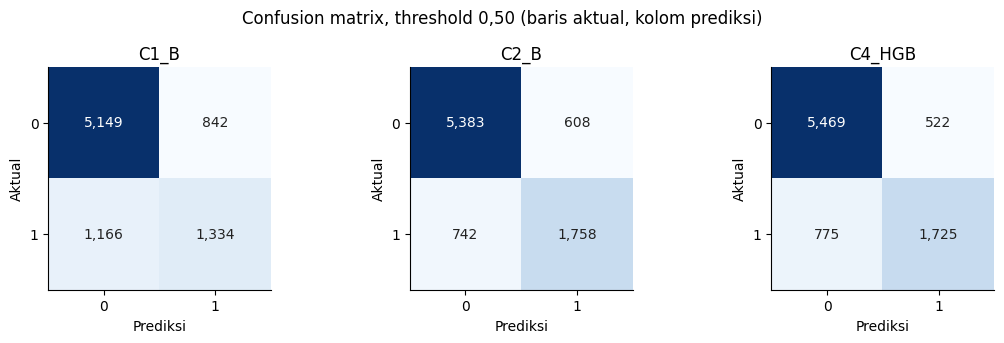

model,C1_B,C2_B,C4_HGB
cycle,,,
76,0.7273,0.7937,0.7968
77,0.7268,0.7916,0.8014
78,0.6773,0.8115,0.8175
79,0.6762,0.8214,0.8213


,equal-cycle Macro F1
model,
C1_B,0.7019
C2_B,0.8046
C4_HGB,0.8093


In [8]:
def one_row_metrics(name, mask=None):
    if mask is None:
        mask = np.ones(len(y_valid), dtype=bool)
    result = binary_metrics(y_valid[mask], probabilities[name][mask], threshold)
    return result

metric_results = {name: one_row_metrics(name) for name in probabilities}
overall_rows = []
class_rows = []
for name, result in metric_results.items():
    m = result
    overall_rows.append({"model": name, "n": m["n"], "Macro F1": m["macro_f1"],
                         "F1 kelas 0": m["per_class"][0]["f1"], "F1 kelas 1": m["per_class"][1]["f1"],
                         "AP": m["average_precision"], "positive aktual": m["positive_rate"],
                         "positive prediksi": m["positive_prediction_rate"]})
    for cls in m["per_class"]:
        class_rows.append({"model": name, "kelas": cls["label"], "support": cls["support"],
                           "precision": cls["precision"], "recall": cls["recall"], "F1": cls["f1"]})
overall_table = pd.DataFrame(overall_rows).set_index("model")
display(overall_table.style.format("{:.4f}", subset=["Macro F1", "F1 kelas 0", "F1 kelas 1", "AP", "positive aktual", "positive prediksi"]))
display(pd.DataFrame(class_rows).style.format({"precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}"}))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, result) in zip(axes, metric_results.items()):
    cm = np.asarray(result["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    ax.set(title=name, xlabel="Prediksi", ylabel="Aktual", xticks=[0, 1], yticks=[0, 1])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, f"{value:,}", ha="center", va="center",
                color="white" if value > cm.max() * 0.55 else "#222222")
fig.suptitle("Confusion matrix, threshold 0,50 (baris aktual, kolom prediksi)")
plt.tight_layout()
plt.show()

cycle_rows = []
for name, p in probabilities.items():
    for cycle in sorted(np.unique(validation_cycles)):
        mask = validation_cycles == cycle
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        cycle_rows.append({"model": name, "cycle": int(cycle), "n": int(mask.sum()),
                           "Macro F1": m["macro_f1"], "prevalence": m["positive_rate"],
                           "positive prediksi": m["positive_prediction_rate"]})
cycle_table = pd.DataFrame(cycle_rows)
display(cycle_table.pivot(index="cycle", columns="model", values="Macro F1").round(4))
equal_cycle = cycle_table.groupby("model")["Macro F1"].mean().rename("equal-cycle Macro F1")
display(equal_cycle.to_frame().round(4))

**Interpretasi hasil W6.** C2_B menunjukkan kemampuan hybrid pada seluruh record; C1_B adalah fallback structured-only; C4_HGB menggabungkan keduanya dengan gate ketersediaan. Ketiga hasil berasal dari record validasi yang sama sehingga perbedaannya dapat dibandingkan secara berpasangan. Periksa class-1 recall bersama precision dan confusion matrix agar kenaikan Macro F1 tidak menyembunyikan pertukaran false positive/false negative.

model,C1_B,C2_B,C4_HGB
kelompok,,,
EF0,0.6715,0.8033,0.8078
EF1,0.7354,0.7970,0.8011
stream kosong,0.7466,0.6775,0.7466
stream tersedia,0.7007,0.8147,0.8147


,kelompok,model,n,Macro F1,F1 kelas 0,F1 kelas 1,FP,FN
0,stream kosong,C1_B,526,0.7466,0.8502,0.6431,40,71
1,stream kosong,C2_B,526,0.6775,0.7363,0.6186,126,38
2,stream kosong,C4_HGB,526,0.7466,0.8502,0.6431,40,71
3,stream tersedia,C1_B,7965,0.7007,0.8360,0.5654,802,1095
4,stream tersedia,C2_B,7965,0.8147,0.8968,0.7326,482,704
5,stream tersedia,C4_HGB,7965,0.8147,0.8968,0.7326,482,704


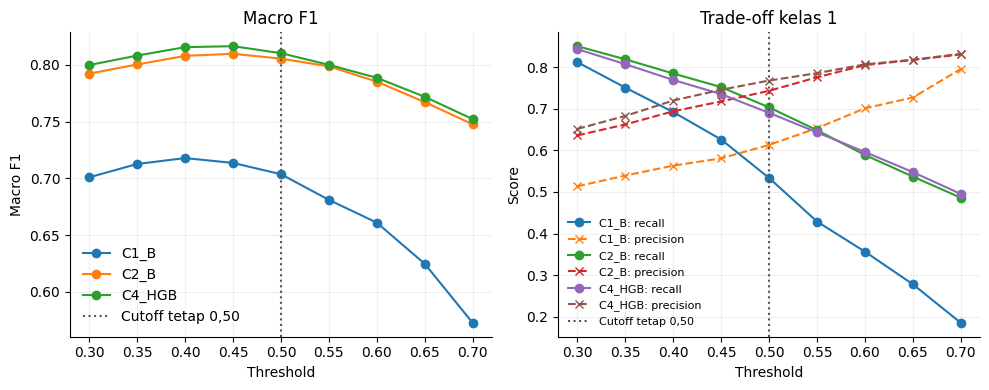

,model,threshold,Macro F1,precision class 1,recall class 1,positive prediction rate
4,C1_B,0.5,0.7037,0.6131,0.5336,0.2563
13,C2_B,0.5,0.8056,0.7430,0.7032,0.2786
22,C4_HGB,0.5,0.8104,0.7677,0.6900,0.2646


In [9]:
subgroup_masks = {
    "stream kosong": missing_valid,
    "stream tersedia": ~missing_valid,
    "EF0": train.loc[valid_mask, "entry_friction"].eq(0).to_numpy(),
    "EF1": train.loc[valid_mask, "entry_friction"].eq(1).to_numpy(),
}
subgroup_rows = []
for group, mask in subgroup_masks.items():
    for name, p in probabilities.items():
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        subgroup_rows.append({"kelompok": group, "model": name, "n": m["n"],
                              "Macro F1": m["macro_f1"], "F1 kelas 0": m["per_class"][0]["f1"],
                              "F1 kelas 1": m["per_class"][1]["f1"],
                              "FP": m["false_positive"], "FN": m["false_negative"]})
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.pivot(index="kelompok", columns="model", values="Macro F1").round(4))
display(subgroup_table[subgroup_table["kelompok"].str.startswith("stream")].round(4))

# Descriptive cutoff sensitivity on the same temporal validation block.
# This grid is not used to choose or replace the frozen 0.50 threshold.
threshold_rows = []
cutoff_grid = np.round(np.arange(0.30, 0.701, 0.05), 2)
for name, p in probabilities.items():
    for cutoff in cutoff_grid:
        m = binary_metrics(y_valid, p, float(cutoff))
        threshold_rows.append({"model": name, "threshold": cutoff, "Macro F1": m["macro_f1"],
                               "precision class 1": m["per_class"][1]["precision"],
                               "recall class 1": m["per_class"][1]["recall"],
                               "positive prediction rate": m["positive_prediction_rate"]})
threshold_table = pd.DataFrame(threshold_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, group in threshold_table.groupby("model"):
    axes[0].plot(group.threshold, group["Macro F1"], marker="o", label=name)
    axes[1].plot(group.threshold, group["recall class 1"], marker="o", label=f"{name}: recall")
    axes[1].plot(group.threshold, group["precision class 1"], marker="x", linestyle="--", label=f"{name}: precision")
for ax in axes:
    ax.axvline(0.50, color="#555555", linestyle=":", label="Cutoff tetap 0,50")
    ax.set_xlabel("Threshold")
    ax.grid(alpha=0.2)
axes[0].set(title="Macro F1", ylabel="Macro F1")
axes[1].set(title="Trade-off kelas 1", ylabel="Score")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
display(threshold_table[threshold_table.threshold.eq(0.50)].round(4))

**Catatan threshold.** Kurva hanya memperlihatkan sensitivitas keputusan pada blok validasi yang sama. Cutoff tidak dipilih dari kurva ini: threshold resmi kandidat tetap 0,50 seperti protokol. Macro F1 memberi bobot sama pada dua kelas; karena itu perubahan positive prediction rate dapat menaikkan recall satu kelas namun sekaligus meningkatkan false positives atau menurunkan F1 kelas lain.

## 5. Kandidat akhir dan bukti Kaggle

Aturan C4_HGB yang dipertahankan:

- `signal_stream` NaN atau kosong setelah `strip()` → gunakan probabilitas C1_B (structured HGB).
- `signal_stream` berisi teks → gunakan probabilitas C2_B (structured + TF-IDF Logistic Regression).
- Keduanya memakai threshold 0,50.

Ini adalah gate deterministik atas ketersediaan fitur. Tidak ada target, hasil validation, atau informasi masa depan dalam pemilihan branch. Pipeline menggunakan fitur structured: `impact_load`, `entry_friction`, `cycle_code`, `scope_pressure`, `text_load`, `scope_trace`, `org_spread`, `module_spread`, `telemetry_flag`, `org_code`, `module_code`, `pattern_code`; C2_B menambahkan `signal_stream`. Kolom ID dan target tidak menjadi predictor. Kolom lain yang tidak diizinkan recipe tidak dipakai; eksklusi ini tidak menyatakan semuanya terbukti leakage.

Bukti submission di bawah dibaca dari manifest committed yang mencatat penerimaan Kaggle. Skor public mengukur sebagian Test dan tetap terpisah dari temporal validation; private score tidak tersedia.

In [10]:
submission_manifest = json.loads(
    (PROJECT_ROOT / "reports/submissions/classification_initial_manifest.json").read_text(encoding="utf-8")
)
kaggle = submission_manifest["kaggle_submission"]
assert submission_manifest["task"] == "classification"
assert kaggle["status"] == "COMPLETE"
assert kaggle["reference"] == 57808225
assert float(kaggle["public_score"]) == 0.82641
candidate_id = "C4_HGB"
assert candidate_id in submission_manifest["model"]["route"]
assert float(submission_manifest["model"]["threshold"]) == 0.50
display(pd.DataFrame([{
    "kandidat": candidate_id,
    "threshold": submission_manifest["model"]["threshold"],
    "status Kaggle": kaggle["status"],
    "public score": kaggle["public_score"],
    "submission ref": kaggle["reference"],
    "private score tersedia": kaggle["private_score"] is not None,
}]))

historical_w6 = pd.DataFrame([
    {"model": name, "W6 probability SHA-256": round2_w6[name]["probability_sha256"],
     "Macro F1": round2_w6[name]["policies"]["fixed_0.5"]["metrics"]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
fresh_w6 = pd.DataFrame([
    {"model": name, "fresh SHA-256": probability_hashes[name],
     "fresh Macro F1": metric_results[name]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
display(historical_w6.merge(fresh_w6, on="model").round(6))

,kandidat,threshold,status Kaggle,public score,submission ref,private score tersedia
0,C4_HGB,0.5,COMPLETE,0.82641,57808225,False


,model,W6 probability SHA-256,Macro F1,fresh SHA-256,fresh Macro F1
0,C1_B,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700
1,C2_B,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571
2,C4_HGB,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384


In [11]:
core_receipt={'task':'classification','fit_cycles':[47,75],'validation_cycles':[76,79],
    'fit_rows':len(fit_rows),'validation_rows':len(valid_rows),'threshold':0.5,
    'metrics':{name:float(result['macro_f1']) for name,result in metric_results.items()},
    'probability_sha256':probability_hashes,'matches_historical_predictions':True,
    'historical_primary_macro_f1':float(r2_primary['C4_HGB']['metrics']['macro_f1']),
    'historical_h12_macro_f1':float(r2_h12['C4_HGB']['metrics']['macro_f1']),
    'kaggle_public_macro_f1':0.82641,'fit_preprocessing_only_train':True,'test_used_in_core':False}
receipt_path=PROJECT_ROOT/'artifacts/samuel_final/classification_core_receipt.json'
receipt_path.parent.mkdir(parents=True,exist_ok=True)
receipt_path.write_text(json.dumps(core_receipt,indent=2)+'\n',encoding='utf-8')

820

### Refit seluruh Train dan official Test (opsional)

Sel berikut dimatikan secara default. Jika kelak dibutuhkan untuk pemeriksaan lokal atas seluruh Test, ubah `RUN_FULL_TRAIN_INFERENCE` menjadi `True` secara eksplisit. Sel akan memfit ulang C2_B/C1_B pada seluruh 50.608 label Train dan menulis CSV lokal yang diperiksa terhadap SampleSubmission. Ia tidak mengunggah file atau membaca label Test.

Refitting semua Train tidak menghasilkan evaluasi baru, sehingga tidak menggantikan metrik temporal. Kandidat yang tercatat telah dikirimkan sebelumnya; jangan mengunggah ulang dari notebook ini.

In [12]:
RUN_FULL_TRAIN_INFERENCE = False
if RUN_FULL_TRAIN_INFERENCE:
    if DATA_FILES["test"] is None or DATA_FILES["sample"] is None:
        raise FileNotFoundError("Official Test.csv dan SampleSubmission.csv diperlukan untuk inference.")
    assert sha256_file(DATA_FILES['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha256_file(DATA_FILES['sample']) == '889f97d69659a64945421d841dcf96e5813020606f29b2992d4b9560cecdcba7'
    test = pd.read_csv(DATA_FILES["test"])
    sample = pd.read_csv(DATA_FILES["sample"])
    assert list(sample.columns) == ["record_id", "artifact_signal"]
    assert len(test) == len(sample) == 29_421
    assert test["record_id"].is_unique and sample["record_id"].is_unique
    assert test["record_id"].tolist() == sample["record_id"].tolist()
    assert 'artifact_signal' not in test and set(test.columns) == set(train.columns) - {'artifact_signal'}
    assert not set(train.record_id) & set(test.record_id) and test.cycle_code.between(80,91).all()
    assert set(X_HYBRID).issubset(test.columns) and set(X_STRUCTURED).issubset(test.columns)

    full_X_hybrid = train.loc[:, X_HYBRID].copy()
    full_X_structured = train.loc[:, X_STRUCTURED].copy()
    full_y = train["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
    full_c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
    full_c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
    with threadpool_limits(limits=2):
        full_c2b.fit(full_X_hybrid, full_y)
        test_p_c2b = full_c2b.predict_proba(test.loc[:, X_HYBRID])
        full_c1b.fit(full_X_structured, full_y)
        test_p_c1b = full_c1b.predict_proba(test.loc[:, X_STRUCTURED])
    test_missing = stream_missing_mask(test[["signal_stream"]])
    test_prob = np.where(test_missing, test_p_c1b, test_p_c2b)
    test_prediction = (test_prob >= 0.50).astype(np.int8)
    assert len(test_prediction) == 29_421 and set(np.unique(test_prediction)).issubset({0, 1})
    submission_preview = pd.DataFrame({"record_id": sample["record_id"], "artifact_signal": test_prediction})
    assert submission_preview.columns.tolist() == sample.columns.tolist()
    assert submission_preview["record_id"].tolist() == sample["record_id"].tolist()
    assert submission_preview["artifact_signal"].notna().all()

    output_path = Path(os.environ.get(
        "SAMUEL_CLASSIFICATION_PREDICTION_PATH",
        PROJECT_ROOT / "artifacts/samuel_final/classification_reproduced.csv",
    )).expanduser()
    if not output_path.is_absolute():
        output_path = PROJECT_ROOT / output_path
    output_path.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes=submission_preview.to_csv(index=False).encode('utf-8')
    if output_path.exists() and output_path.read_bytes() != csv_bytes:
        raise FileExistsError('Output lokal sebelumnya berbeda; periksa sebelum menggantinya.')
    output_path.write_bytes(csv_bytes)
    print("CSV lokal dibuat; belum diunggah:", output_path.resolve())
    print("Jumlah baris:", len(submission_preview), "| class 1:", int(test_prediction.sum()))
else:
    print("Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.")

Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.


## Kesimpulan dan keterbatasan

Pada Classification TP2, teks memberikan tambahan informasi dibanding structured-only. C2_B meningkatkan primary pooled Macro F1 menjadi 0,8206, tetapi validasi missing-stream menunjukkan trade-off yang memotivasi C4_HGB. Routing mempertahankan branch C2_B untuk stream-present dan menggunakan C1_B untuk stream-missing; pada seluruh development primary hasil Round 2 adalah Macro F1 0,8255, dengan pooled H12 0,7968. Candidate public Kaggle score 0,82641 berasal dari sebagian Test dan bukan pembuktian bahwa skor temporal akan terulang.

**Jawaban metodologis:** availability routing dipilih karena dua representasi mempunyai perilaku berbeda ketika teks hilang. Macro F1 memperhatikan kedua kelas. Threshold 0,50 dipertahankan karena eksperimen threshold dari inner history tidak konsisten memperbaiki primary, sementara cutoff tetap sederhana dan sudah dipakai pada submission yang diterima.

Batas yang perlu dibawa ke demo: (1) seluruh cycle 56–79 sudah dilihat selama development; W6 refit adalah reproduksi pada blok yang sama, bukan test baru; (2) H12 memakai ulang record primary; (3) subgroup missing lebih kecil; (4) public score hanya melihat bagian Test, private score tidak diketahui; (5) preprocessing dan routing tidak membuktikan hubungan kausal; (6) generalisasi cycle 80–91 belum bisa dinilai tanpa label.

### Bukti dan reproducibility

- Official rubric: TP2 KASDAD, hlm. 2–4 (EDA dan approach end-to-end), hlm. 6 (kontribusi individual), hlm. 7–9 (format notebook dan Restart & Run All), hlm. 10 (pengembangan dari TP1; skor lebih tinggi/model lebih kompleks tidak diwajibkan).
- Historical reports: [`Round 1 findings`](../../reports/classification_round1/FINDINGS.md), [`Round 2 findings`](../../reports/classification_round2/FINDINGS.md), [`Round 2 comparison tables`](../../reports/classification_round2/comparison_tables.md).
- Verified receipts: `reports/classification_round1/verification.json`, `reports/classification_round2/verification.json`; submission: `reports/submissions/classification_initial_manifest.json`.
- Required files: repository source under `src/`, dependencies from `requirements.txt`, official data under `data/raw/classification/` or `TP2_DATA_DIR` pointing to a parent directory containing `classification/`.
- Notebook execution does not read ignored `experiments/runs/` caches. The temporal fit is rerun directly from Train. Full-Train inference is explicitly disabled by default. No Kaggle API or credential is used.

Notebook ini merangkum pendekatan Classification Samuel Indriano pada tahap final review. Kelayakan akhir pengumpulan tetap menunggu review pengguna.